# Exploratory Data Analysis and Visualization
**CSC 366: Principles of Data Science | Group 02**

This notebook uses the final dataset, `jobs_features.csv`, to answer the project question: **What do entry-level software jobs actually require in terms of skills, experience, and pay?**

**Sections:**
- Setup and summary statistics
- Most common skills in entry-level postings
- Least common skills
- Entry-level vs. startup skills
- Skills over time
- Years of experience required
- Degree requirements
- Salary by location
- Remote vs. on-site pay
- Skills and salary
- The two sources compared

SerpAPI entry-level postings (867 postings with an entry-level job title) are the main source for every entry-level question. Hacker News US posts are used as a comparison group, since most of them are from startups hiring experienced engineers. The two sources are analyzed separately rather than combined, because they describe different parts of the job market.

**AI assistance:** AI (Claude) was used to help understand the data before each chart was made, for example by checking how the data was distributed and pointing out issues such as posts listing more skills over time. It also helped format the charts so they were clear and presentable. The observations under each chart were written by the group.

**Upload `jobs_features.csv` to the Colab files panel before running.**

## Load the data and set up the groups

The data is loaded, and three groups are set up that are used throughout this notebook:

- **`analysis`**: `keep_for_analysis == True` (no duplicates, no non-job comments). The starting point for everything.
- **`serpEntry`**: SerpAPI postings with an entry-level title (`seniority == "Entry"`). Used for the main entry-level questions.
- **`hnUS`**: Hacker News posts located in the US. Used as the comparison group.

`skillColumns` is a list of the 38 `has_` skill columns, so they can be used together in one line instead of typed out one by one.

**AI assistance:** AI (Claude) recommended setting up these groups and the `skillColumns` list once at the start, so every later section could reuse them. This made the analysis much simpler, since each chart only needs one filter instead of repeating the same conditions every time.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

In [ ]:
dfJobs = pd.read_csv("jobs_features.csv")
print(f"Full dataset: {dfJobs.shape}")

# Unique, real job posts only
analysis = dfJobs[dfJobs["keep_for_analysis"] == True]

# Main group: SerpAPI postings with an entry-level title
serpEntry = analysis[(analysis["source"] == "serpapi") & (analysis["seniority"] == "Entry")]

# Comparison group: Hacker News posts in the US
hnUS = analysis[(analysis["source"] == "hackernews") & (analysis["region"] == "US")]


print(f"Rows kept for analysis: {len(analysis)}")
print(f"SerpAPI entry-level postings: {len(serpEntry)}")
print(f"Hacker News US posts: {len(hnUS)}")


Full dataset: (9437, 77)
Rows kept for analysis: 6866
SerpAPI entry-level postings: 867
Hacker News US posts: 3103


/tmp/ipykernel_948/1575417286.py:1: DtypeWarning: Columns (1,4,18,19) have mixed types. Specify dtype option on import or set low_memory=False.
  dfJobs = pd.read_csv("jobs_features.csv")


The two groups not add up to 6,866 is because:
- `serpEntry` leaves out SerpAPI postings with senior or unclear titles
- `hnUS` leaves out posts outside the US or with an unknown location.

## Summary statistics

The five-number summary (min, Q1, median, Q3, max) for the three main numeric variables: salary, years of experience required, and number of skills per posting. Each one is shown for SerpAPI entry-level postings and Hacker News US posts side by side.

Salary only uses full-time postings that list a salary and are not flagged as outliers.

In [ ]:
# Salaries
# Full-time postings that are not salary outliers
serpFullTime = serpEntry[(serpEntry["job_type"] == "Full-time") & (serpEntry["is_salary_outlier"] == False)]
hnFullTime = hnUS[(hnUS["job_type"] == "Full-time") & (hnUS["is_salary_outlier"] == False)]

# Five-number summary of yearly salary for both groups
pd.DataFrame({
    "SerpAPI entry-level": serpFullTime["salary_min_yearly"].describe(),
    "Hacker News (US)": hnFullTime["salary_min_yearly"].describe(),
}).round(1)

,SerpAPI entry-level,Hacker News (US)
count,378.0,517.0
mean,90266.8,151054.1
std,28466.4,33008.0
min,18000.0,65000.0
25%,70000.0,130000.0
50%,90000.0,150000.0
75%,101000.0,175000.0
max,180000.0,250000.0


In [ ]:
# Years of experience
pd.DataFrame({
    "SerpAPI entry-level": serpEntry["years_required"].describe(),
    "Hacker News (US)": hnUS["years_required"].describe(),
}).round(1)

,SerpAPI entry-level,Hacker News (US)
count,218.0,286.0
mean,1.7,5.2
std,2.1,2.6
min,0.0,1.0
25%,0.0,3.0
50%,1.0,5.0
75%,2.0,5.8
max,10.0,15.0


In [ ]:
# Number of skills wanted in job description
pd.DataFrame({
    "SerpAPI entry-level": serpEntry["skill_count"].describe(),
    "Hacker News (US)": hnUS["skill_count"].describe(),
}).round(1)

,SerpAPI entry-level,Hacker News (US)
count,867.0,3103.0
mean,5.7,2.9
std,4.3,2.8
min,0.0,0.0
25%,2.0,1.0
50%,5.0,2.0
75%,9.0,5.0
max,22.0,19.0


## Most common skills in entry-level postings

For this section, we wanted to find out which skills show up the most in entry-level job postings. Since each `has_` column is either True or False, taking the `.mean()` of a column gives the share of postings that mention that skill (True counts as 1 and False counts as 0).

**AI assistance:** AI (Claude) suggested using `.mean()` on the True/False columns as a simple way to get the percentage for every skill at once.

In [29]:
# Readable names for the skill columns, used in every chart
skillNames = {
    "has_python": "Python", "has_java": "Java", "has_javascript": "JavaScript",
    "has_typescript": "TypeScript", "has_cpp": "C++", "has_csharp_net": "C#/.NET",
    "has_go": "Go", "has_rust": "Rust", "has_ruby": "Ruby", "has_sql": "SQL",
    "has_postgres": "Postgres", "has_nosql": "NoSQL", "has_react": "React",
    "has_angular": "Angular", "has_nodejs": "Node.js", "has_nextjs": "Next.js",
    "has_html_css": "HTML/CSS", "has_django_flask_fastapi": "Django/Flask/FastAPI",
    "has_spring": "Spring", "has_apis": "APIs", "has_aws": "AWS", "has_azure": "Azure",
    "has_gcp": "GCP", "has_docker": "Docker", "has_kubernetes": "Kubernetes",
    "has_terraform": "Terraform", "has_ci_cd": "CI/CD", "has_linux": "Linux",
    "has_git": "Git", "has_machine_learning": "Machine learning",
    "has_pytorch_tensorflow": "PyTorch/TensorFlow", "has_ai_llms": "AI/LLMs",
    "has_ai_agents": "AI agents", "has_langchain_rag": "LangChain/RAG", "has_mcp": "MCP",
    "has_embedded_rtos": "Embedded/RTOS", "has_agile": "Agile", "has_c": "C",
}


# Collect every column name that starts with "has_"
skillColumns = []

for column in dfJobs.columns:
    if column.startswith("has_"):
        skillColumns.append(column)

# % of entry-level postings that mention each skill
skillShare = (serpEntry[skillColumns].mean() * 100).round(1)

# Use readable names, then sort from most to least common
skillShare = skillShare.rename(index=skillNames).sort_values(ascending=False)

skillShare.head(15)

,0
Python,50.5
Java,47.9
APIs,38.8
JavaScript,33.8
C++,29.8
Machine learning,28.0
Git,27.8
SQL,24.8
Agile,19.6
Docker,19.6


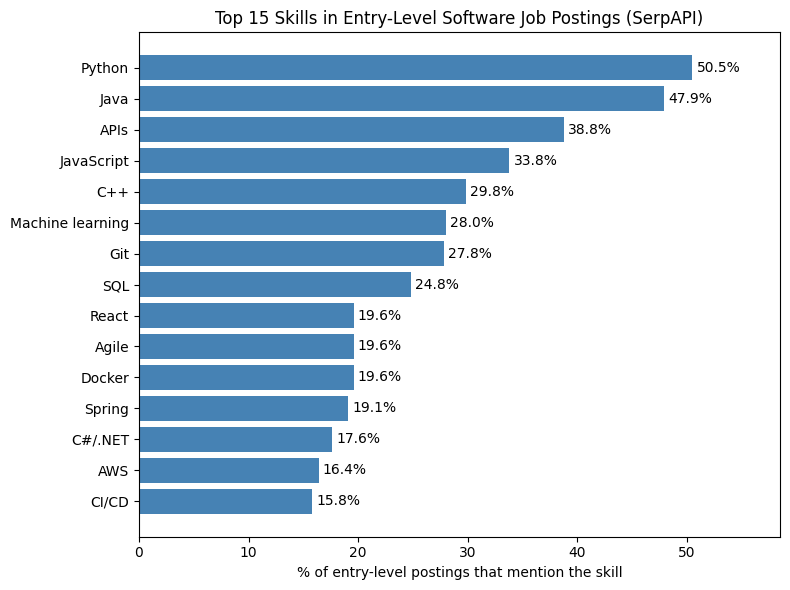

In [ ]:
# Top 15 skills, sorted smallest to largest
top15 = skillShare.head(15).sort_values()

plt.figure(figsize=(8, 6))
bars = plt.barh(top15.index, top15.values, color="steelblue")
plt.bar_label(bars, padding=3, fmt="%.1f%%")
plt.xlim(0, top15.max() + 8)
plt.title("Top 15 Skills in Entry-Level Software Job Postings (SerpAPI)")
plt.xlabel("% of entry-level postings that mention the skill")
plt.tight_layout()
plt.show()

**Observations:**

We were surprised by how far ahead Python and Java were, with both appearing in about half of all entry-level postings and the next skill, APIs, about 10 points behind.

Since AI is very popular right now, we expected it to rank near the top. Machine learning was the only AI skill in the top 15, but when all AI-related skills are counted together (machine learning, AI/LLMs, AI agents, PyTorch/TensorFlow, LangChain/RAG, and MCP), 36.0% of postings mention at least one, which would place AI fourth overall.


## Least common skills in entry-level postings

The 10 least common skills from the 38 tracked skills. Since the tracked skills were chosen because they were already fairly common, a second check searches the entry-level descriptions for other languages that were not tracked, to see which ones are rarely asked for at all.

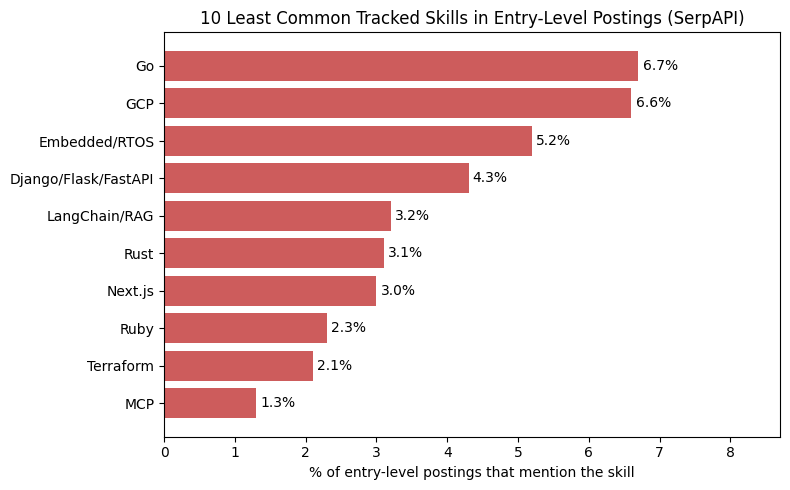

In [ ]:
# Bottom 10 tracked skills, smallest at the bottom
bottom10 = skillShare.tail(10).sort_values()

plt.figure(figsize=(8, 5))
bars = plt.barh(bottom10.index, bottom10.values, color="indianred")
plt.bar_label(bars, padding=3, fmt="%.1f%%")
plt.xlim(0, bottom10.max() + 2)
plt.title("10 Least Common Tracked Skills in Entry-Level Postings (SerpAPI)")
plt.xlabel("% of entry-level postings that mention the skill")
plt.tight_layout()
plt.show()

**Observations**

## LangChain (and RAG)

**LangChain** is an open-source framework, mainly used with Python and JavaScript, for building apps that use large language models (LLMs). It handles the behind-the-scenes work, like sending prompts, connecting multiple AI steps, and using outside tools.

**RAG (Retrieval-Augmented Generation)** is a technique often used with LangChain. Before answering a question, the AI searches relevant documents or databases and uses that information to generate a response. This lets the AI answer questions using information it wasn't originally trained on.

**Example:** A customer-support chatbot that searches a company's help articles before answering questions.

## MCP (Model Context Protocol)

**MCP** is an open standard introduced by Anthropic in late 2024. It allows AI assistants to connect to outside tools and data, such as Google Drive, databases, calendars, and GitHub.

Instead of developers building separate connections for every app, MCP provides a **common standard**, similar to how USB allows different devices to connect to computers.

**Example:** An AI assistant connecting to Google Drive to read files or Figma to work with designs.

In [ ]:
# Other languages, searched directly in the entry-level descriptions
# Other languages, searched directly in the entry-level descriptions
# AI assistance: AI (Claude) suggested also checking languages that were left out
# of the 38 tracked skills (because they appeared in fewer than 5% of postings),
# just to see how rarely they are actually asked for.
otherSkills = {
    "Kotlin": r"\bkotlin\b",
    "Swift": r"\bswift\b",
    "PHP": r"\bphp\b",
    "Scala": r"\bscala\b",
    "Perl": r"\bperl\b",
    "MATLAB": r"\bmatlab\b",
    "Dart/Flutter": r"\bdart\b|\bflutter\b",
    "Haskell": r"\bhaskell\b",
    "Elixir": r"\belixir\b",
    "Julia": r"\bjulia\b",
    "Zig": r"\bzig\b",
    "COBOL": r"\bcobol\b",
    "Fortran": r"\bfortran\b",
}

descriptionsLower = serpEntry["description"].str.lower()

# % of entry-level postings that mention each language
otherShare = {}
for skill, pattern in otherSkills.items():
    otherShare[skill] = round(descriptionsLower.str.contains(pattern, regex=True).mean() * 100, 1)

otherShare = pd.Series(otherShare).sort_values(ascending=False)
otherShare

,0
PHP,1.8
Kotlin,1.7
Swift,1.5
Scala,1.4
Perl,1.2
MATLAB,0.6
Dart/Flutter,0.2
Elixir,0.2
COBOL,0.1
Haskell,0.0


**Observation**

Languages such as COBOL and PHP appear rarely in entry-level postings, even though they still run many existing systems. This raises the question of whether these roles offer stronger job stability, since a low number of postings could reflect low turnover rather than low demand. This project’s data cannot measure job stability, so testing this would require other sources, such as job tenure or layoff data by technology.

## Skills over time (Hacker News)

Even though most Hacker News posts come from startups, it is the only dataset with dates across 24 months (Nov 2024 to Oct 2026). This makes it useful for seeing how the demand for different skills has changed over time.

Before comparing skills, we checked whether the posts themselves changed. Posts later in the period listed more skills on average, which would make almost every skill look like it was rising. To adjust for this, each skill is measured as a **share of all skill mentions** in that period, instead of the share of posts that mention it. This shows which skills are taking up more or less of the conversation.

**AI assistance:** AI (Claude) measuring each skill as a share of all skill mentions to adjust for it.

In [ ]:
# All Hacker News job posts (all regions), with the month each was posted
hnAll = analysis[analysis["source"] == "hackernews"].copy()
hnAll["month"] = pd.to_datetime(hnAll["posted_date"]).dt.to_period("M")

# First 6 months vs. last 6 months
earlyPosts = hnAll[hnAll["month"] <= "2025-04"]
latePosts = hnAll[hnAll["month"] >= "2026-05"]

print(f"Early posts: {len(earlyPosts)}, late posts: {len(latePosts)}")
print(f"Average skills per post (early): {earlyPosts['skill_count'].mean():.2f}")
print(f"Average skills per post (late):  {latePosts['skill_count'].mean():.2f}")

Early posts: 1545, late posts: 1185
Average skills per post (early): 2.35
Average skills per post (late):  3.03


In [ ]:
# Each skill's share of ALL skill mentions in each period
earlyShare = earlyPosts[skillColumns].sum() / earlyPosts[skillColumns].sum().sum() * 100
lateShare = latePosts[skillColumns].sum() / latePosts[skillColumns].sum().sum() * 100

change = pd.DataFrame({"Early (%)": earlyShare, "Late (%)": lateShare}).round(1).rename(index=skillNames)
change["Change"] = (change["Late (%)"] - change["Early (%)"]).round(1)
change = change.sort_values("Change", ascending=False)

print("Rising:")
print(change.head(6))
print("\nFalling:")
print(change.tail(6))

Rising:
               Early (%)  Late (%)  Change
AI agents            2.3       5.9     3.6
MCP                  0.0       1.1     1.1
LangChain/RAG        0.4       1.4     1.0
APIs                 5.1       5.9     0.8
CI/CD                1.1       1.8     0.7
Rust                 2.4       2.9     0.5

Falling:
                  Early (%)  Late (%)  Change
GCP                     2.2       1.7    -0.5
TypeScript              8.2       7.6    -0.6
JavaScript              1.8       1.1    -0.7
AWS                     6.1       5.0    -1.1
Machine learning        5.8       4.7    -1.1
React                   9.5       7.2    -2.3


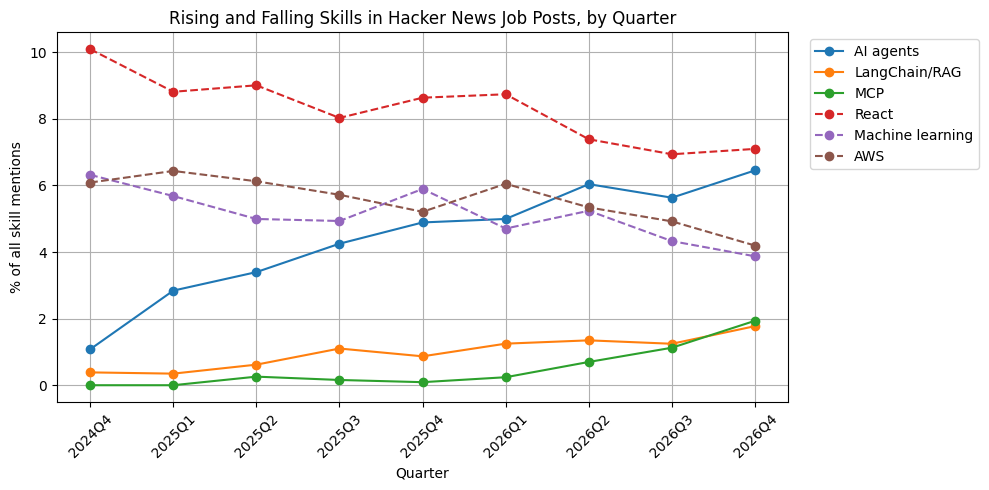

In [ ]:
# AI assistance: AI (Claude) helped set up this chart, since there was a lot to keep
# track of: grouping posts by quarter, adjusting for posts listing more skills over time,
# and showing rising skills (solid lines) and falling skills (dashed lines) on one chart.

# Group posts by quarter (3-month periods)
hnAll["quarter"] = pd.to_datetime(hnAll["posted_date"]).dt.to_period("Q")

# Share of all skill mentions, per quarter
mentionsPerQuarter = hnAll.groupby("quarter")[skillColumns].sum()
totalPerQuarter = mentionsPerQuarter.sum(axis=1)
shareByQuarter = (mentionsPerQuarter.div(totalPerQuarter, axis=0) * 100).rename(columns=skillNames)

plt.figure(figsize=(10, 5))

# Rising skills: solid lines
for skill in ["AI agents", "LangChain/RAG", "MCP"]:
    plt.plot(shareByQuarter.index.astype(str), shareByQuarter[skill], marker="o", label=skill)

# Falling skills: dashed lines
for skill in ["React", "Machine learning", "AWS"]:
    plt.plot(shareByQuarter.index.astype(str), shareByQuarter[skill], marker="o", linestyle="--", label=skill)

plt.title("Rising and Falling Skills in Hacker News Job Posts, by Quarter")
plt.xlabel("Quarter")
plt.ylabel("% of all skill mentions")
plt.xticks(rotation=45)
plt.grid(True)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")   # legend outside so it doesn't cover the lines
plt.tight_layout()
plt.show()

## Years of experience required

This section looks at one of our main questions: how much experience do "entry-level" jobs actually ask for?

For this, we only used postings with an entry-level job title (`serpEntry`). We didn't use the `is_entry_level` column, because it already counts postings that ask for 2 years or less as entry-level. Using it here would partly decide the answer before we even looked at the data.

We also only included postings that actually state a number of years. Postings that don't mention experience were left out instead of being counted as 0.

In [ ]:
# How many entry-level postings state years of experience at all?
statesYears = serpEntry["years_required"].notna()
print(f"Entry-level postings: {len(serpEntry)}")
print(f"Postings that state years of experience: {statesYears.sum()} ({statesYears.mean() * 100:.1f}%)")

# Of the postings that do state a number
yearsStated = serpEntry["years_required"].dropna()
print(f"Of those, asking for 2+ years: {(yearsStated >= 2).mean() * 100:.1f}%")
print(f"Of those, asking for 3+ years: {(yearsStated >= 3).mean() * 100:.1f}%")

Entry-level postings: 867
Postings that state years of experience: 218 (25.1%)
Of those, asking for 2+ years: 38.1%
Of those, asking for 3+ years: 17.9%


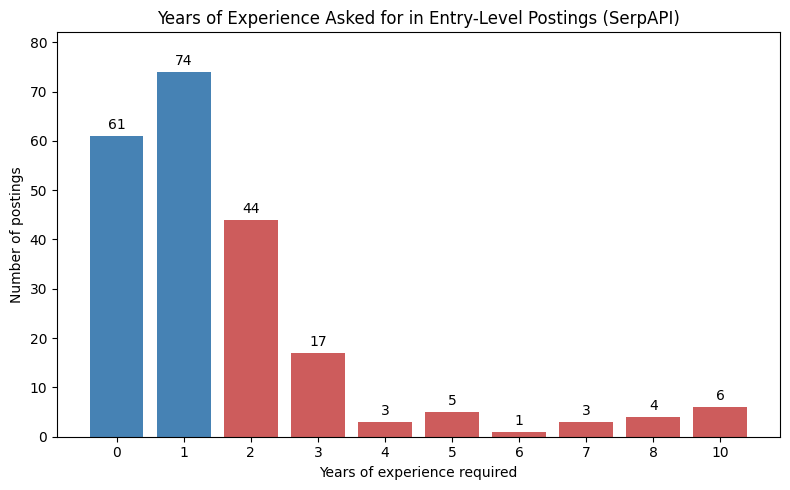

In [ ]:
# Number of postings for each number of years
yearsCounts = yearsStated.astype(int).value_counts().sort_index()

# Blue = under 2 years, red = 2 or more
colors = ["steelblue" if years < 2 else "indianred" for years in yearsCounts.index]

plt.figure(figsize=(8, 5))
bars = plt.bar(yearsCounts.index.astype(str), yearsCounts.values, color=colors)
plt.bar_label(bars, padding=3)
plt.ylim(0, yearsCounts.max() + 8)          # room for the labels on top
plt.title("Years of Experience Asked for in Entry-Level Postings (SerpAPI)")
plt.xlabel("Years of experience required")
plt.ylabel("Number of postings")
plt.tight_layout()
plt.show()

**Observations:**

We noticed 10 of the 218 entry-level posting required 8 or more years of experience. In some cases, this was because our extraction picked up experience requirements for applicants without a degree or from the "nice to have" section. However, some postings actually required 8–10 years of experience despite being labeled entry-level. This shows that job titles do not always match the actual experience requirements.

## Degree requirements

How do entry-level postings talk about a college degree? Each posting is labeled by `degree_status`:

- **Required**
- **Preferred**
- **Pursuing** (current students)
- **Mentioned** (no clear wording)
- **Not mentioned**.

When we checked some of the postings using `.head()`, we noticed that not all the labels were correct. Out of the 20 postings we checked, about 15 were labeled correctly.

In [ ]:
# Count each degree label, in a fixed order (strongest requirement first)
degreeOrder = ["Required", "Preferred", "Pursuing", "Mentioned", "Not mentioned"]

# AI assistance: AI (Claude) suggested .reindex(), which puts the counts in the
# order of degreeOrder instead of sorting them from most to least common.
degreeCounts = serpEntry["degree_status"].value_counts().reindex(degreeOrder)
degreePercent = (degreeCounts / degreeCounts.sum() * 100).round(1)

print(pd.DataFrame({"Postings": degreeCounts, "Percent": degreePercent}))
print()
print(f"Mention a degree at all: {serpEntry['mentions_degree'].mean() * 100:.1f}%")
print(f"Clearly require a degree: {serpEntry['needs_degree'].mean() * 100:.1f}%")
print(f"Accept 'or equivalent experience': {serpEntry['requirements'].fillna('').str.contains('equivalent').mean() * 100:.1f}%")
print()
# Degree numbers for Hacker News US posts, for comparison
print(f"HN posts that mention a degree at all: {hnUS['mentions_degree'].mean() * 100:.1f}%")
print(f"HN posts that clearly require a degree: {hnUS['needs_degree'].mean() * 100:.1f}%")

               Postings  Percent
degree_status                   
Required            303     34.9
Preferred            98     11.3
Pursuing             35      4.0
Mentioned           138     15.9
Not mentioned       293     33.8

Mention a degree at all: 66.2%
Clearly require a degree: 34.9%
Accept 'or equivalent experience': 14.2%

HN posts that mention a degree at all: 2.2%
HN posts that clearly require a degree: 0.5%


**Observations:**

We noticed that (2/3) of entry-level postings mention a degree, but only about (1/3) clearly require one. Our group decided combining Required + Preferred (46%) gives a safer “employers want a degree” number than either label alone.

Startup posts on Hacker News almost never mention a degree (2.2%), compared to two-thirds of entry-level postings on Google Jobs, suggesting that startups put less emphasis on degrees when advertising roles.

## Salary by location

Median entry-level salary by state. This uses SerpAPI entry-level postings that are full-time, list a salary, and are not flagged as outliers (378 postings).

Only states with at least 15 salaries are shown, since a median from just a few postings would not be reliable. The number of salaries behind each median is shown next to its bar.

Entry-level full-time salaries: 378


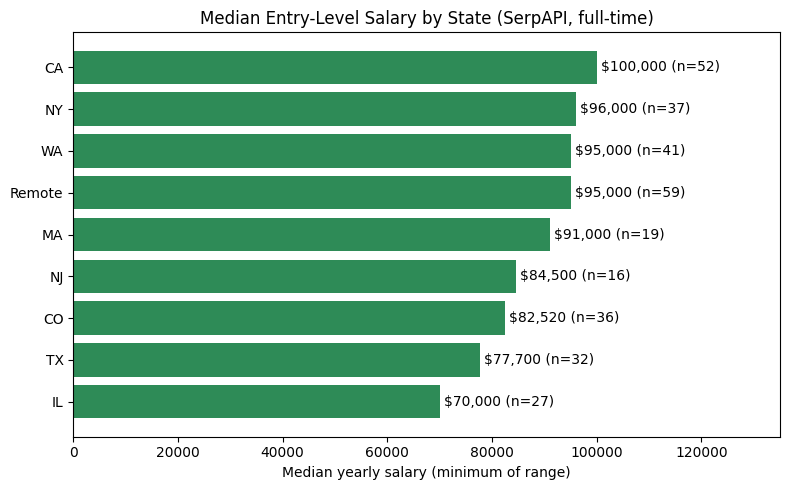

In [ ]:
# Entry-level, full-time, with a salary, filtered for outliers
entrySalary = serpEntry[
    (serpEntry["job_type"] == "Full-time") &
    (serpEntry["is_salary_outlier"] == False) &
    (serpEntry["salary_min_yearly"].notna())
]
print(f"Entry-level full-time salaries: {len(entrySalary)}")

# Count and median salary for each state
salaryByState = entrySalary.groupby("state")["salary_min_yearly"].agg(["count", "median"])

# Keep states with at least 15 salaries,leave out "Unknown"
salaryByState = salaryByState[(salaryByState["count"] >= 15) & (salaryByState.index != "Unknown")]
salaryByState = salaryByState.sort_values("median")

# Label: median and count
labels = [f"${median:,.0f} (n={count})" for median, count in zip(salaryByState["median"], salaryByState["count"])]

plt.figure(figsize=(8, 5))
bars = plt.barh(salaryByState.index, salaryByState["median"], color="seagreen")
plt.bar_label(bars, labels=labels, padding=3)
plt.xlim(0, salaryByState["median"].max() * 1.35)     # room for the labels
plt.title("Median Entry-Level Salary by State (SerpAPI, full-time)")
plt.xlabel("Median yearly salary (minimum of range)")
plt.tight_layout()
plt.show()

**Observations:**

Looking at the chart, we noticed that California had the highest median starting salary at \$100K, while Illinois had the lowest at \$70K. This \$30K difference could be partly explained by the higher cost of living in California. New York, Washington, and remote jobs (listed as their own group) were all around \$95K.

We also noticed that New Jersey (16 postings) and Massachusetts (19 postings) had much smaller sample sizes compared to California (52 postings), so their results might not be as reliable.

For this chart, we used the minimum salary from each posted range since it gives us a better idea of what a new graduate might expect to earn when starting out.

## Remote vs. on-site pay

This compares the median entry-level salary for remote jobs and on-site jobs, using the full-time salaries from the previous chart.


         count   median
On-site    319  87200.0
Remote      59  95000.0


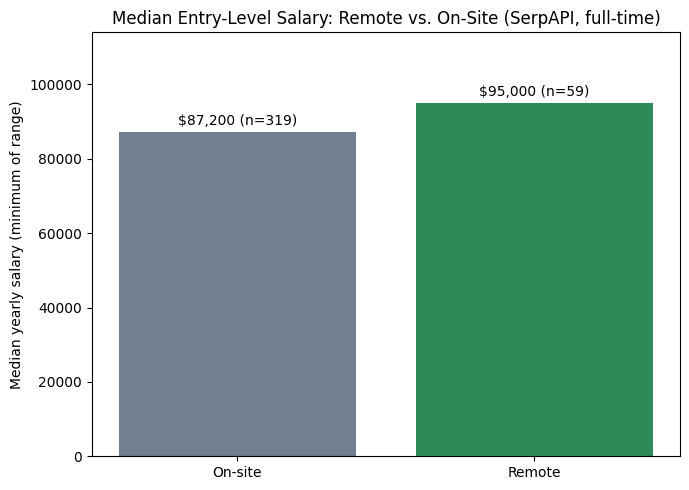

In [ ]:
# Count and median salary for remote and on-site jobs
remoteSalary = entrySalary.groupby("is_remote")["salary_min_yearly"].agg(["count", "median"])
remoteSalary.index = ["On-site", "Remote"]          # False -> On-site, True -> Remote
print(remoteSalary)

# Bar chart of the two medians, labeled with the count
labels = [f"${median:,.0f} (n={count})" for median, count in zip(remoteSalary["median"], remoteSalary["count"])]

plt.figure(figsize=(7, 5))
bars = plt.bar(remoteSalary.index, remoteSalary["median"], color=["slategray", "seagreen"])
plt.bar_label(bars, labels=labels, padding=3)
plt.ylim(0, remoteSalary["median"].max() * 1.2)
plt.title("Median Entry-Level Salary: Remote vs. On-Site (SerpAPI, full-time)")
plt.ylabel("Median yearly salary (minimum of range)")
plt.tight_layout()
plt.show()

**Observations:**

We noticed that remote jobs had a slightly higher median salary (\$95,000) compared to on-site jobs (\$87,200). However, our sample size for remote jobs was much smaller, with only 59 postings compared to 319 on-site postings. Because of this, and because the difference changed across versions of our data, we are not confident in saying that remote jobs actually pay more than on-site jobs.

## Skills and salary

Do postings that mention certain skills pay more? For each of 8 common skills, the full-time entry-level salaries are split into two groups: postings that mention the skill and postings that don't. The median of each group is compared.

This shows which skills are **associated** with higher pay, not which skills **cause** higher pay. Postings often list several skills together, so the groups overlap.

In [26]:
# 8 common skills to compare
topSkillColumns = ["has_python", "has_java", "has_apis", "has_javascript",
                   "has_cpp", "has_machine_learning", "has_sql", "has_aws"]

# For each skill: median salary of postings that mention it vs. all other postings,
# and how many salaries are in each group
rows = []
for column in topSkillColumns:
    mentionsSkill = entrySalary[entrySalary[column] == True]["salary_min_yearly"]
    otherPostings = entrySalary[entrySalary[column] == False]["salary_min_yearly"]
    rows.append({
        "Skill": skillNames[column],
        "Mentions skill": mentionsSkill.median(),
        "Don't mention (False)": otherPostings.median(),
        "n mentions": len(mentionsSkill),
        "n other": len(otherPostings),
    })

skillSalary = pd.DataFrame(rows).set_index("Skill")
skillSalary["Difference"] = skillSalary["Mentions skill"] - skillSalary["Don't mention (False)"]

# Biggest pay difference at the top
skillSalary.sort_values("Difference", ascending=False)

,Mentions skill,Don't mention (False),n mentions,n other,Difference
Skill,,,,,
Python,95000.0,80000.000,194,184,15000.000
Machine learning,95000.0,82519.615,98,280,12480.385
Java,95000.0,83000.000,177,201,12000.000
AWS,95000.0,86000.000,75,303,9000.000
JavaScript,95000.0,87025.000,96,282,7975.000
APIs,91250.0,85925.000,132,246,5325.000
C++,90000.0,88500.000,96,282,1500.000
SQL,85000.0,90000.000,107,271,-5000.000


**Observations:**

- We noticed that postings mentioning Python had the largest pay difference.
- Machine learning  and Java also showed higher median salaries.
- SQL was the only skill linked to lower pay.

Our reasoning for SQL having a decrease is becasue SQL often appears in data and IT support roles (we only searched for software engineering roles).

## The two sources compared

For our last section, we wanted to compare the salaries from both datasets side by side. Both charts only use full-time salaries that were not flagged as outliers, and the dashed line marks the median for each group.

This comparison shows why we analyzed SerpAPI and Hacker News separately instead of combining them: the two datasets describe different parts of the job market, so mixing them would have made entry-level salaries look much higher than they really are.

**AI assistance:** AI (Claude) helped set up the two side-by-side histograms using subplots, including giving both charts the same salary ranges so they could be compared fairly and adding the dashed median lines.

SerpAPI entry-level: 378 salaries, median $90,000
Hacker News (US):    517 salaries, median $150,000


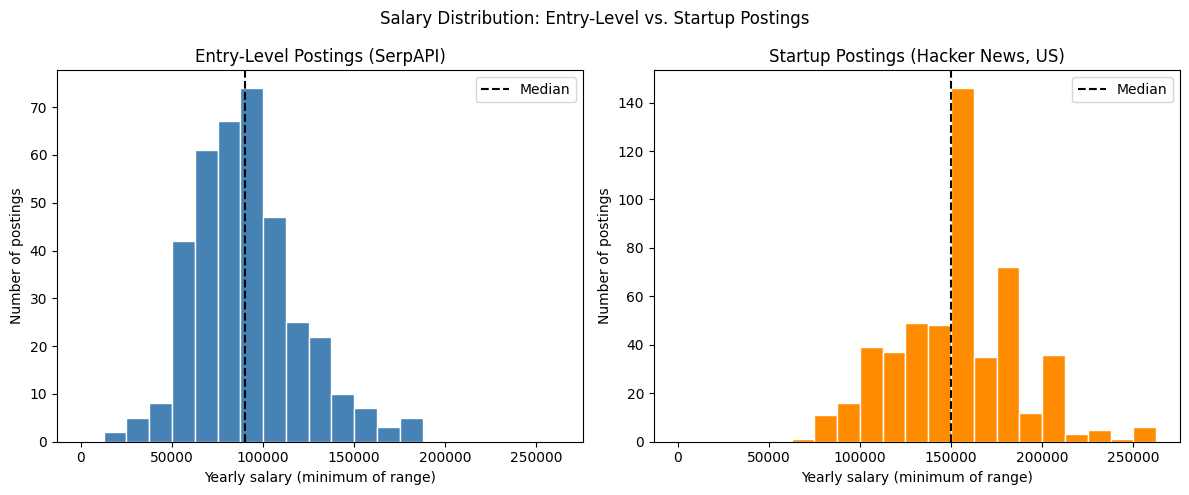

In [27]:
# Hacker News US full-time salaries (same filters as entrySalary)
hnSalary = hnUS[(hnUS["job_type"] == "Full-time") & (hnUS["is_salary_outlier"] == False) & (hnUS["salary_min_yearly"].notna())]

print(f"SerpAPI entry-level: {len(entrySalary)} salaries, median ${entrySalary['salary_min_yearly'].median():,.0f}")
print(f"Hacker News (US):    {len(hnSalary)} salaries, median ${hnSalary['salary_min_yearly'].median():,.0f}")

# Same salary ranges (bins) for both charts so they can be compared: $0 to $275K in $12.5K steps
bins = np.arange(0, 275000, 12500)

# Two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: SerpAPI entry-level
axes[0].hist(entrySalary["salary_min_yearly"], bins=bins, color="steelblue", edgecolor="white")
axes[0].axvline(entrySalary["salary_min_yearly"].median(), color="black", linestyle="--", label="Median")
axes[0].set_title("Entry-Level Postings (SerpAPI)")
axes[0].set_xlabel("Yearly salary (minimum of range)")
axes[0].set_ylabel("Number of postings")
axes[0].legend()

# Right: Hacker News US
axes[1].hist(hnSalary["salary_min_yearly"], bins=bins, color="darkorange", edgecolor="white")
axes[1].axvline(hnSalary["salary_min_yearly"].median(), color="black", linestyle="--", label="Median")
axes[1].set_title("Startup Postings (Hacker News, US)")
axes[1].set_xlabel("Yearly salary (minimum of range)")
axes[1].set_ylabel("Number of postings")
axes[1].legend()

plt.suptitle("Salary Distribution: Entry-Level vs. Startup Postings")
plt.tight_layout()
plt.show()

**Observations:**

Looking at the two charts, we noticed a pretty large difference in salaries. SerpAPI had a median salary of \$90K, while Hacker News (HN) had a median of \$150K, a \$60K difference. Most entry-level salaries were between \$50K and \$110K, while most HN salaries were between \$100K and \$200K.

We also noticed that the SerpAPI salaries followed a smoother shape, while HN had spikes at round numbers like \$150K, \$180K, and \$200K. This could be because startups tend to list salaries in round numbers.

One reason HN salaries are higher is that the dataset includes jobs from all experience levels, with about 32% being senior positions. Many of these jobs are also from startups in major tech cities. Because of this, we can't really say that startups pay entry-level employees more, since the two datasets represent different groups of jobs.

## Summary of Findings

**Our Question:** What do entry-level software jobs actually require in terms of skills, experience, and pay?

**Skills:** We found that Python (50.5%) and Java (47.9%) were the most common programming languages, appearing in about half of the entry-level postings. AI-related skills were also fairly common when grouped together (36.0%), but newer tools like AI agents, LangChain, and MCP were still rarely mentioned. When we looked at Hacker News, we noticed that startups focused more on React, TypeScript, Postgres, and AI agents. Over the past two years, AI agent tools also had the biggest increase, while React, machine learning, and AWS made up a smaller share of the skills mentioned.

**Experience:** One thing that surprised us was that only about 1 in 4 entry-level postings actually mentioned a specific number of years of experience. Of those that did, 38% asked for at least 2 years, and 18% asked for 3 or more. We even found a few jobs labeled as entry-level that asked for 8–10 years of experience. This shows that just because a job is labeled entry-level doesn't always mean it is meant for someone with little experience.

**Degrees:** We found that about two-thirds of entry-level postings mentioned a degree, but only about one-third clearly required one. Around 14% also accepted equivalent work experience instead of a degree.

**Pay:** The median entry-level salary was \$90,000, but it varied depending on location. For example, Illinois had a median of \$70,000, while California had \$100,000. Remote jobs had a slightly higher median than on-site jobs, but our remote sample was too small to confidently say they pay more. We also noticed that jobs mentioning Python, machine learning, or Java tended to have higher median salaries, while jobs mentioning SQL had lower ones. Hacker News had a much higher median salary of \$150,000, but since those postings included all experience levels, it wouldn't be fair to directly compare them to entry-level jobs.

**Why It Matters:** Based on what we found, we think CS students looking for their first job should focus on building strong programming skills, especially in Python and Java. Learning tools like Git and working with APIs would also be useful since they appeared frequently in job postings. We also learned that some entry-level jobs still expect experience, so internships and personal projects could help students prepare. Another interesting finding was that not every job strictly required a degree, and salaries could be very different depending on where the job was located.

**Limitations:** There are a few things to keep in mind with our results. Only about half of the entry-level postings included salary information, so our salary comparisons don't represent every job. We also used keyword matching to identify skills and requirements, which means some information might have been missed or incorrectly labeled.